# 4. Hallazgos: equidad territorial y evolución en el tiempo

* ¿Se resuelven más lento las quejas en ciertos boroughs o códigos postales **controlando por tipo de queja**?
* ¿Mejora o empeora el tiempo de resolución mes a mes?

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

from nyc311.config import ARCHIVO_LIMPIO, ARCHIVO_RESULTADOS, DIR_FIGURAS, DIR_TABLAS

res = json.loads(ARCHIVO_RESULTADOS.read_text(encoding="utf-8"))
tabla = lambda nombre: pd.read_csv(DIR_TABLAS / f"{nombre}.csv")
figura = lambda nombre: display(Image(filename=str(DIR_FIGURAS / nombre)))

## 4.1 Equidad territorial (estandarización indirecta)

Resultado: «cerrada en ≤ 7 días», observado para todas las solicitudes (la cohorte termina 26 días antes del corte
y la censura es solo administrativa). Esperado = tasa de toda la ciudad en su celda tipo de queja × descriptor.
O/E < 1: se cierran menos de lo que su mezcla de quejas predice.

In [2]:
eq = tabla("equidad_boroughs")
eq[["borough", "n", "pct_cerradas_7d", "pct_esperado_7d", "o_entre_e", "ic_inf", "ic_sup"]]

,borough,n,pct_cerradas_7d,pct_esperado_7d,o_entre_e,ic_inf,ic_sup
0,BRONX,1656465,81.404,81.556,0.998,0.998,0.999
1,BROOKLYN,2277063,80.861,81.213,0.996,0.995,0.996
2,MANHATTAN,1482757,78.407,78.138,1.003,1.003,1.004
3,QUEENS,1829773,83.258,83.284,1.000,0.999,1.000
4,SIN DATO,6475,52.062,53.640,0.971,0.957,0.984
5,STATEN ISLAND,292145,80.932,78.546,1.030,1.029,1.032


El mismo O/E a horizontes cortos muestra **dónde** está la brecha: el Bronx cierra menos de lo esperado en la primera
hora y alcanza lo esperado hacia las 24 horas. Es lo mismo que mostraban los HR por ventana del modelo de Cox, ahora
sin el supuesto PH.

In [3]:
tabla("equidad_boroughs_horizontes").pivot(index="borough", columns="horizonte", values="o_entre_e")[
    ["1 h", "3 h", "8 h", "1 día", "7 días"]]

horizonte,1 h,3 h,8 h,1 día,7 días
borough,,,,,
BRONX,0.822,0.889,0.954,1.004,0.998
BROOKLYN,1.057,1.035,1.008,0.986,0.996
MANHATTAN,1.129,1.076,1.031,1.014,1.003
QUEENS,0.995,0.991,1.000,1.000,1.000
SIN DATO,0.908,0.998,1.006,1.005,0.971
STATEN ISLAND,0.959,1.052,1.055,1.027,1.030


In [4]:
z = tabla("equidad_zip")
e = res["equidad"]
print(f"ZIP analizados (≥ 1.000 solicitudes): {e['n_zip_analizados']} · significativos con FDR 5 %: {e['n_zip_significativos']}")
print(f"Más lentos de lo esperado: {e['n_zip_lentos']} · más rápidos: {e['n_zip_rapidos']}")
print(f"O/E entre el percentil 5 y el 95: {e['oe_zip_p05']:.3f} – {e['oe_zip_p95']:.3f}")
z.head(8)[["zip", "borough", "n", "pct_cerradas_7d", "pct_esperado_7d", "o_entre_e", "ic_inf", "ic_sup"]]

ZIP analizados (≥ 1.000 solicitudes): 181 · significativos con FDR 5 %: 114
Más lentos de lo esperado: 56 · más rápidos: 58
O/E entre el percentil 5 y el 95: 0.980 – 1.025


,zip,borough,n,pct_cerradas_7d,pct_esperado_7d,o_entre_e,ic_inf,ic_sup
0,10044,MANHATTAN,1924,55.925,63.352,0.883,0.858,0.907
1,10037,MANHATTAN,22180,69.062,71.507,0.966,0.960,0.972
2,10475,BRONX,10764,75.938,78.346,0.969,0.962,0.976
3,10459,BRONX,55257,72.622,74.433,0.976,0.972,0.979
4,11249,BROOKLYN,29366,78.989,80.852,0.977,0.973,0.981
5,11222,BROOKLYN,61045,84.308,86.198,0.978,0.976,0.980
6,11426,QUEENS,10890,72.608,74.235,0.978,0.970,0.986
7,11362,QUEENS,8089,75.658,77.336,0.978,0.970,0.987


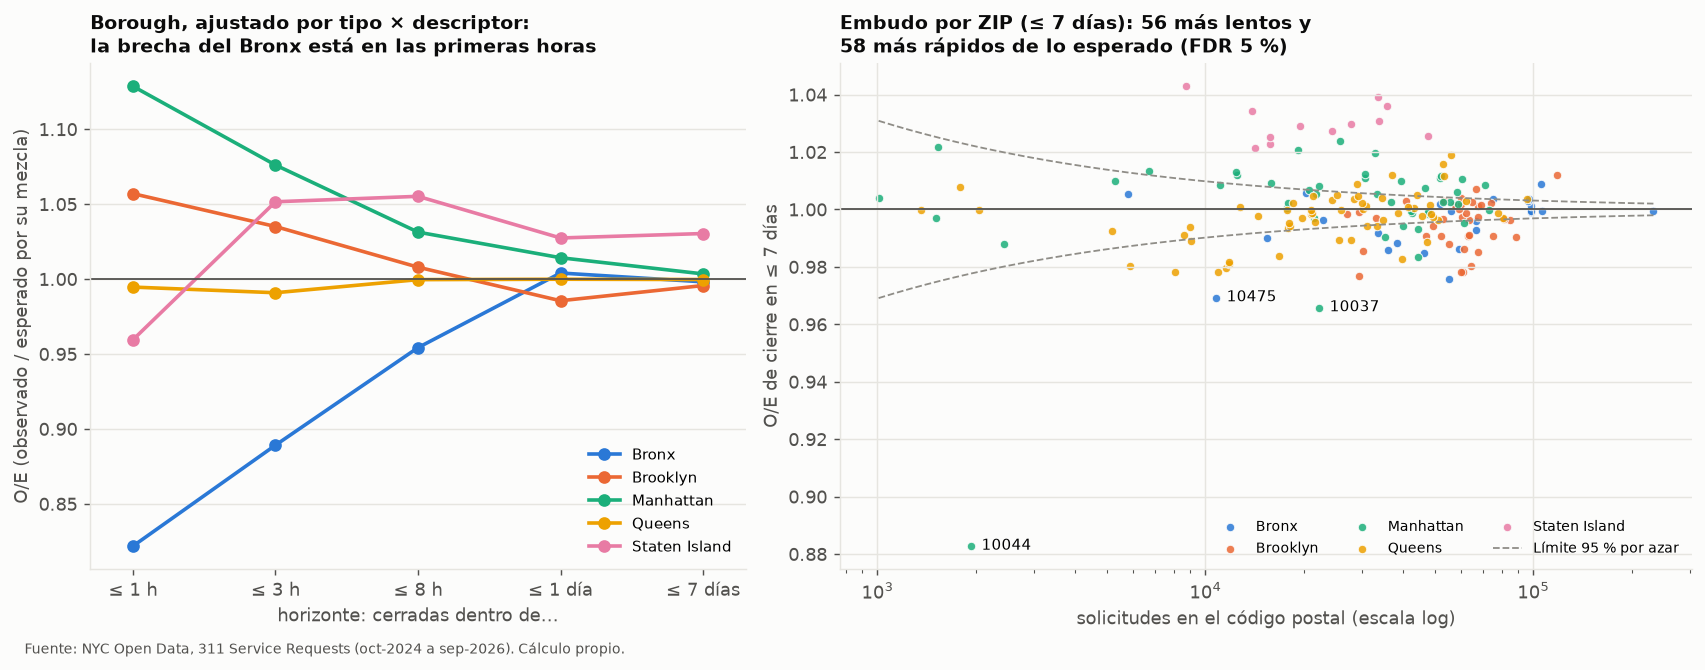

In [5]:
figura("08_equidad_territorial.png")

**Limitaciones (correlación no es causalidad).** Un O/E bajo puede deberse a menos recursos, pero también a
casos más difíciles dentro de la misma celda (edificios más viejos, problemas recurrentes), a duplicados que se
cierran juntos, a diferencias en cómo cada agencia registra el «cierre» o a quién reporta (el 311 mide demanda
reportada, no necesidad real). No se usan datos socioeconómicos, así que no se puede atribuir la diferencia a
ingreso o composición étnica.

## 4.2 Evolución mensual

In [6]:
m = tabla("evolucion_mensual")
m[["mes", "n", "mediana_km_dias", "pct_cerradas_7d", "pct_esperado_7d", "o_entre_e"]].assign(
    mediana_horas=lambda d: 24 * d["mediana_km_dias"])

,mes,n,mediana_km_dias,pct_cerradas_7d,pct_esperado_7d,o_entre_e,mediana_horas
0,2024-10,303385,0.333,82.533,80.001,1.032,8.004
1,2024-11,291157,0.576,79.989,81.191,0.985,13.823
2,2024-12,312681,0.786,82.634,82.830,0.998,18.861
3,2025-01,347030,0.640,85.386,84.309,1.013,15.364
4,2025-02,254407,0.609,83.599,82.212,1.017,14.627
5,2025-03,279453,0.367,82.902,81.907,1.012,8.806
6,2025-04,270388,0.309,82.409,81.048,1.017,7.426
7,2025-05,294573,0.183,83.110,81.524,1.019,4.395
8,2025-06,306384,0.155,81.935,81.153,1.010,3.731
9,2025-07,315816,0.206,79.858,80.275,0.995,4.955


In [7]:
ev = res["evolucion"]
pd.DataFrame(ev["periodos"]).T

,n,mediana_km_horas,pct_cerradas_7d,o_entre_e
oct-2024 a sep-2025,"3,581,884.000",8.043,82.393,1.011
oct-2025 a sep-2026,"3,962,794.000",10.010,79.850,0.990


In [8]:
tabla('evolucion_agencias_anual')

,agencia,mediana_anio1_dias,mediana_anio2_dias,cambio_pct
0,DEP,0.994,0.953,-4.123
1,DHS,0.339,0.308,-9.149
2,DOB,14.349,9.503,-33.776
3,DOHMH,1.102,13.237,"1,100.731"
4,DOT,1.976,2.905,47.043
5,DPR,19.102,18.952,-0.787
6,DSNY,1.320,1.674,26.812
7,HPD,3.657,4.301,17.605
8,NYPD,0.056,0.056,0.622
9,Otras,89.068,115.478,29.652


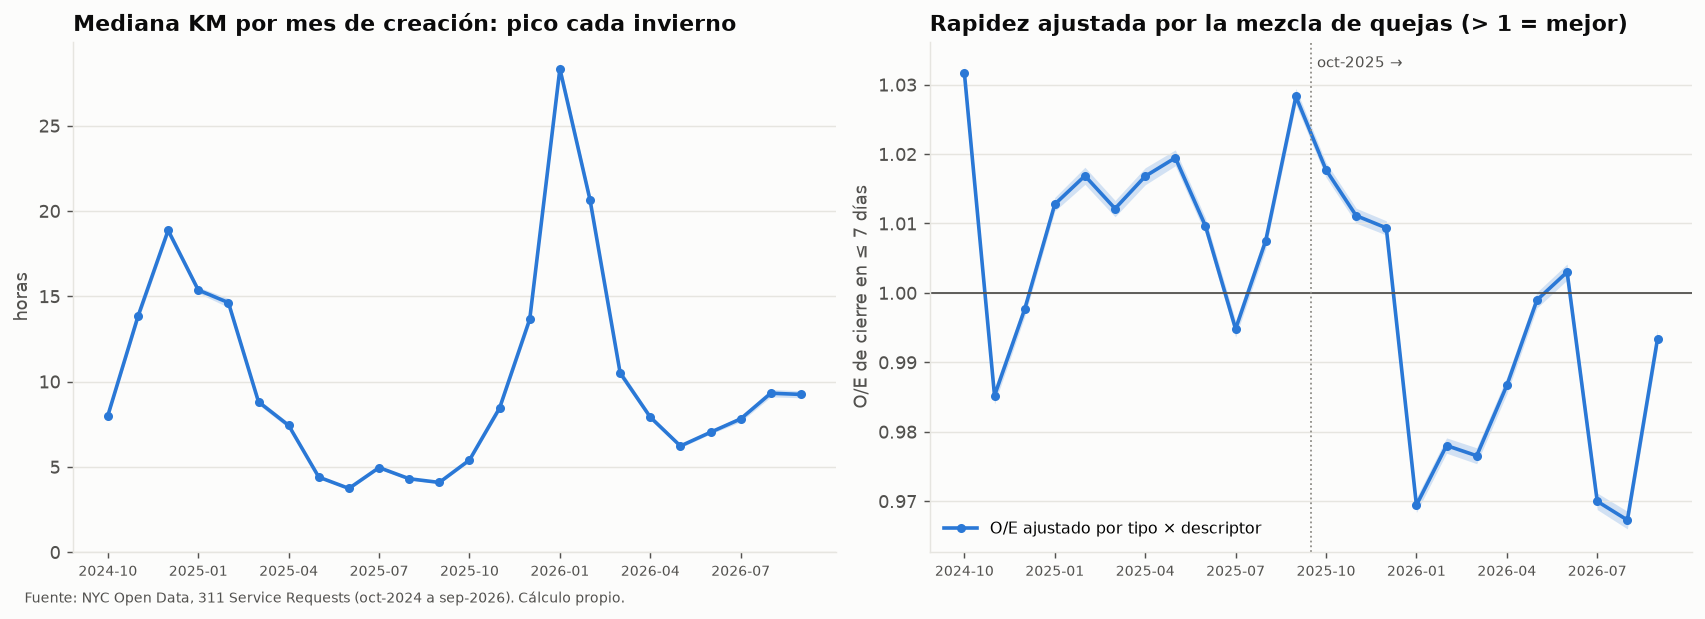

In [9]:
figura("09_evolucion_mensual.png")

**Lectura.** La mediana sube cada invierno porque cambia la **mezcla**: las quejas de calefacción y agua caliente
(HPD), que tardan días, se disparan con el frío. Por eso la tendencia se juzga con el O/E ajustado por tipo ×
descriptor, que compara cada mes con lo que su mezcla de quejas predice.